In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
FIG = Path("../reports/fraud/figures"); FIG.mkdir(parents=True, exist_ok=True)
df = pd.read_csv("../data/raw/paysim/PS_20174392719_1491204439457_log.csv")
print(df.shape, df.isna().sum().sum(), "missing values")
df.head()

(6362620, 11) 0 missing values


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [2]:
print(df.isFraud.value_counts())
print(f"{df.isFraud.mean():.4%} of transactions are fraud")

isFraud
0    6354407
1       8213
Name: count, dtype: int64
0.1291% of transactions are fraud


In [3]:
t = df.groupby("type").agg(n=("isFraud", "size"), frauds=("isFraud", "sum"))
t["fraud_rate"] = t.frauds / t.n
t

,n,frauds,fraud_rate
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2237500,4116,0.001840
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,532909,4097,0.007688


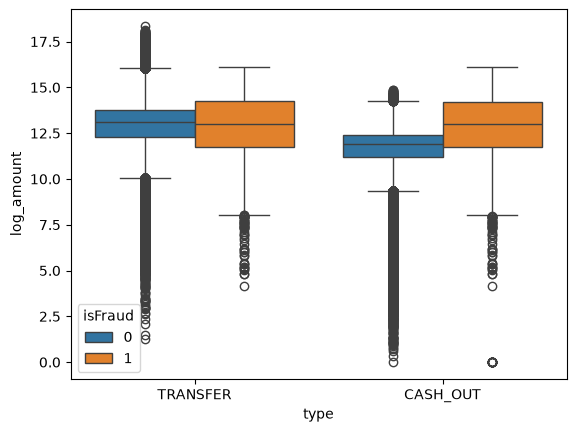

In [4]:
d = df[df.type.isin(["TRANSFER", "CASH_OUT"])].assign(log_amount=lambda x: np.log1p(x.amount))
sns.boxplot(data=d, x="type", y="log_amount", hue="isFraud")
plt.savefig(FIG / "amount_by_fraud.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
print(df.groupby("isFraud").isFlaggedFraud.sum())
emptied = (df.newbalanceOrig == 0) & (df.oldbalanceOrg > 0)
print(pd.crosstab(emptied, df.isFraud, normalize="columns"))
df["errBalOrig"] = df.newbalanceOrig + df.amount - df.oldbalanceOrg
print(df.groupby("isFraud").errBalOrig.describe())
print("unique senders / rows:", df.nameOrig.nunique() / len(df))

isFraud
0     0
1    16
Name: isFlaggedFraud, dtype: int64
isFraud         0         1
row_0                      
False    0.761965  0.024473
True     0.238035  0.975527
             count           mean            std           min       25%  \
isFraud                                                                    
0        6354407.0  201338.558109  606928.890826 -1.000000e-02  3034.305   
1           8213.0   10692.325265  265146.131130 -7.450581e-09     0.000   

              50%        75%          max  
isFraud                                    
0        69049.31  249953.43  92445516.64  
1            0.00       0.00  10000000.00  
unique senders / rows: 0.9985362947967975


In [6]:
df["hour"] = df.step % 24
print(df.groupby("hour").isFraud.mean().round(4))


hour
0     0.0042
1     0.0132
2     0.0413
3     0.1624
4     0.2208
5     0.2230
6     0.1047
7     0.0365
8     0.0137
9     0.0012
10    0.0009
11    0.0007
12    0.0007
13    0.0007
14    0.0008
15    0.0008
16    0.0008
17    0.0008
18    0.0006
19    0.0005
20    0.0006
21    0.0014
22    0.0018
23    0.0023
Name: isFraud, dtype: float64
